# Spatial leakage test: how should we split the data?

Nearby wells have similar nitrate levels. If a test well has close neighbors in the training data, we risk data leakage and overstating the predictive power of our model.

We use the approach found in [*Estimation of aquifer scale proportion using equal area grids: Assessment of regional scale groundwater quality*](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2010WR009321) to divide our map into a square grid. We then perform group k-fold splits, keeping each grid cell intact in the splitting. We evaluate the data leakage by comparing a k-nearest-neighbors model to one that outputs the training mean. Any skill it shows indicates that information is leaking through the split.

In [16]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.model_selection import KFold, GroupKFold
from sklearn.neighbors import KNeighborsRegressor

from src.evaluation import splits, leakage
from src.shared import spatial

NITRATE_PATH = ROOT / "notebooks" / "groundwater" / "groundwater_nitrate_clean.csv"
BOUNDARY_PATH = ROOT / "data" / "watershed_boundary" / "salinas_huc8.gpkg"
WBD_URL = "https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer"
FIGURES = ROOT / "results" / "evaluation"
FIGURES.mkdir(parents=True, exist_ok=True)


In [17]:
df = pd.read_csv(NITRATE_PATH, parse_dates=["gm_samp_collection_date"])
exceeds = df["nitrate_mg_L"] > leakage.THRESHOLD_MG_L

print(f"{len(df):,} samples from {df['gm_well_id'].nunique():,} wells")
print("Samples per year:", df["gm_samp_collection_date"].dt.year.value_counts().sort_index().to_dict())
print(f"Share above {leakage.THRESHOLD_MG_L} mg/L: {exceeds.mean():.1%}")


5,280 samples from 1,993 wells
Samples per year: {2022: 1455, 2023: 1298, 2024: 1252, 2025: 1275}
Share above 10 mg/L: 33.7%


In [18]:
wells = df.drop_duplicates("gm_well_id")
xy_wells = leakage.projected_xy(wells, "gm_latitude", "gm_longitude")
nearest = cKDTree(xy_wells).query(xy_wells, k=2)[0][:, 1]

print("Distance to the nearest other well (m): "
      f"25% within {np.percentile(nearest, 25):.0f}, "
      f"median {np.median(nearest):.0f}, 75% within {np.percentile(nearest, 75):.0f}")


Distance to the nearest other well (m): 25% within 20, median 194, 75% within 434


In [19]:
def folds_from(splitter, groups=None):
    """Turn a scikit-learn splitter into one fold number per row."""
    folds = np.empty(len(df), dtype=int)
    for k, (_, test) in enumerate(splitter.split(df, groups=groups)):
        folds[test] = k
    return folds

schemes = {
    "random rows": folds_from(KFold(5, shuffle=True, random_state=0)),
    "grouped by well": folds_from(GroupKFold(5), groups=df["gm_well_id"]),
}
for km in [1, 2, 5, 10, 15, 20, 25, 30, 35, 40]:
    cells = splits.assign_grid_cells(df, cell_size_m=km * 1000)["cell"]
    schemes[f"{km} km blocks"] = splits.spatial_folds(cells, exceeds)


In [20]:
table = leakage.leakage_table(df, schemes)
table.round(3)

,rmse_log_location_only,rmse_log_no_information,skill,accuracy_location_only,accuracy_majority_class
random rows,0.487,1.212,0.598,0.931,0.661
grouped by well,0.925,1.212,0.237,0.804,0.661
1 km blocks,1.019,1.212,0.159,0.768,0.661
2 km blocks,1.113,1.212,0.082,0.737,0.661
5 km blocks,1.232,1.213,-0.016,0.694,0.661
10 km blocks,1.241,1.213,-0.023,0.686,0.661
15 km blocks,1.226,1.213,-0.011,0.697,0.661
20 km blocks,1.332,1.226,-0.086,0.689,0.661
25 km blocks,1.292,1.269,-0.018,0.645,0.661
30 km blocks,1.262,1.253,-0.007,0.629,0.661


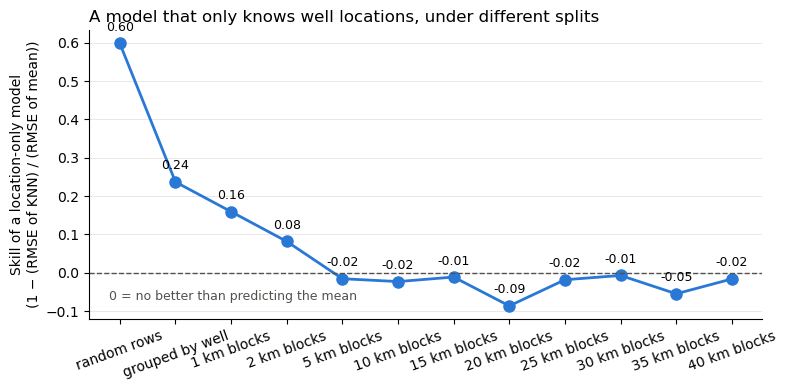

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(table.index)
ax.plot(names, table["skill"], marker="o", color="#2a78d6", linewidth=2, markersize=8)
ax.axhline(0, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.2, -0.045, "0 = no better than predicting the mean",
        color="#52514e", fontsize=9, ha="left", va="top")
for i, s in enumerate(table["skill"]):
    ax.annotate(f"{s:.2f}", (i, s), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9)

ax.set_ylabel("Skill of a location-only model\n(1 − (RMSE of KNN) / (RMSE of mean))")
ax.set_title("A model that only knows well locations, under different splits", loc="left")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(FIGURES / "leakage_skill_by_split.png", dpi=150, bbox_inches="tight")
plt.show()


- **Random rows / grouped by well:** location alone gives real skill. Grouping by well removes the same-well leak, but test wells still have training neighbours a few hundred metres away.
- **5–10 km blocks:** skill ≈ 0, so local copying is gone. This matches the distance at which nitrate values stop being correlated (about 5–7.5 km).
- **> 10 km blocks:** skill appears to be uncorrelated to size, with a notable drop at 20 km but otherwise close to 0.

**Decision: 10 km equal-area cells.**


In [7]:
df = df.join(splits.assign_grid_cells(df, cell_size_m=10_000))
df["fold"] = splits.spatial_folds(df["cell"], exceeds)

for train, test in splits.iter_folds(df["fold"]):
    splits.check_split(df, train, test)
print("No well or cell appears in both train and test in any fold.")

df.groupby("fold").agg(
    samples=("nitrate_mg_L", "size"),
    wells=("gm_well_id", "nunique"),
    cells=("cell", "nunique"),
    share_above_10=("nitrate_mg_L", lambda s: (s > 10).mean()),
).round(3)


No well or cell appears in both train and test in any fold.


,samples,wells,cells,share_above_10
fold,,,,
0,1035,388,7,0.327
1,972,367,15,0.335
2,1143,408,6,0.346
3,1041,430,11,0.337
4,1089,400,13,0.338


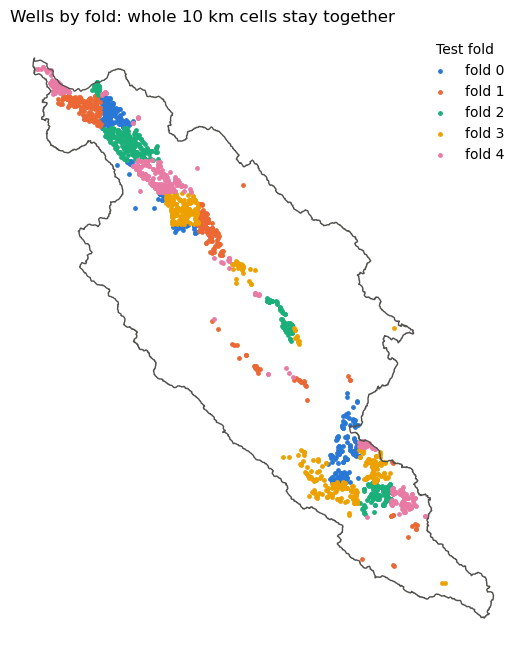

In [8]:
boundary = (spatial.load_boundary(BOUNDARY_PATH) if BOUNDARY_PATH.exists()
            else spatial.fetch_huc8(WBD_URL, "18060005"))

wells = df.drop_duplicates("gm_well_id")
points = gpd.GeoDataFrame(wells, geometry=gpd.points_from_xy(wells.gm_longitude, wells.gm_latitude),
                          crs="EPSG:4326").to_crs(splits.EQUAL_AREA_CRS)
fold_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

fig, ax = plt.subplots(figsize=(7, 8))
boundary.to_crs(splits.EQUAL_AREA_CRS).boundary.plot(ax=ax, color="#52514e", linewidth=1)
for k, color in enumerate(fold_colors):
    points[points["fold"] == k].plot(ax=ax, color=color, markersize=6, label=f"fold {k}")
ax.legend(title="Test fold", loc="upper right", frameon=False)
ax.set_title("Wells by fold: whole 10 km cells stay together", loc="left")
ax.set_axis_off()
fig.savefig(FIGURES / "spatial_folds_map.png", dpi=150, bbox_inches="tight")
plt.show()


In [9]:
xy_all = leakage.projected_xy(df, "gm_latitude", "gm_longitude")
y = np.log1p(df["nitrate_mg_L"].to_numpy())

def location_only_scores(pairs):
    """Fit the location-only and mean models on each (train, test) pair; score all test rows together."""
    loc_pred = np.full(len(y), np.nan)
    mean_pred = np.full(len(y), np.nan)
    for train, test in pairs:
        knn = KNeighborsRegressor(n_neighbors=5, weights="distance").fit(xy_all[train], y[train])
        loc_pred[test] = knn.predict(xy_all[test])
        mean_pred[test] = y[train].mean()
    tested = ~np.isnan(loc_pred)
    scores = leakage.summarize(y[tested], loc_pred[tested], mean_pred[tested],
                               to_mg_l=np.expm1, scale_name="log")
    return {"test samples": int(tested.sum()), **scores}

dates = df["gm_samp_collection_date"]
space_time_pairs = []
for k in np.unique(df["fold"]):
    test_cells = df.loc[df["fold"] == k, "cell"].unique()
    space_time_pairs.append(splits.space_time_split(dates, df["cell"], [2025], test_cells))

pd.DataFrame({
    "spatial CV (10 km)": location_only_scores(splits.iter_folds(df["fold"])),
    "time split (test 2025)": location_only_scores([splits.time_split(dates, [2025])]),
    "space-time (10 km, 2025)": location_only_scores(space_time_pairs),
}).T.round(3)


,test samples,rmse_log_location_only,rmse_log_no_information,skill,accuracy_location_only,accuracy_majority_class
spatial CV (10 km),5280.0,1.241,1.213,-0.023,0.686,0.661
time split (test 2025),1275.0,0.411,1.230,0.666,0.940,0.675
"space-time (10 km, 2025)",1275.0,1.224,1.231,0.006,0.693,0.675


- **Time split:** high skill. With the same wells in train and test, the model remembers each well. This
  measures forecasting at known wells, not prediction at new places.
- **Spatial CV and space-time:** no skill from location alone, so any skill a real model shows there comes from
  its features. **Space-time is closest to infrastructure placement** (next year, unsampled places).

1. Split by **10 km equal-area grid cells**, not by well.
2. Balance folds on the share above 10 mg/L (`StratifiedGroupKFold`).
3. Report the three scenarios separately; use **space-time** as the headline result.
4. Rerun this notebook whenever the split or the data changes.
